In [1]:
!pip install spacy pandas matplotlib seaborn

In [2]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 29.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
import spacy
from spacy import displacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
nlp = spacy.load("en_core_web_sm")

print("spaCy model loaded successfully")

spaCy model loaded successfully


In [5]:
text = """
On March 14, 2025, environmental scientist Asha Mehta
attended the Global Clean Energy Summit in Pune, India.

The event was organized by Green Future Foundation
and supported by engineer Rahul Verma from Jaipur.

The foundation announced an investment of $2.5 million
to install solar panels across 120 schools in Maharashtra.

According to the report, the project aims to reduce
carbon emissions by 35 percent by December 2027.

Minister Arjun Sharma praised the initiative and
announced an additional budget of $500,000 for the project.
"""

print(text)


On March 14, 2025, environmental scientist Asha Mehta
attended the Global Clean Energy Summit in Pune, India.

The event was organized by Green Future Foundation
and supported by engineer Rahul Verma from Jaipur.

The foundation announced an investment of $2.5 million
to install solar panels across 120 schools in Maharashtra.

According to the report, the project aims to reduce
carbon emissions by 35 percent by December 2027.

Minister Arjun Sharma praised the initiative and
announced an additional budget of $500,000 for the project.



In [6]:
doc = nlp(text)

print("Text processed successfully")

Text processed successfully


In [7]:
data = []

for ent in doc.ents:
    data.append({
        "Text": ent.text,
        "Entity Label": ent.label_,
        "Description": spacy.explain(ent.label_)
    })

df_entities = pd.DataFrame(data)

print("=== EXTRACTED ENTITIES ===")

display(df_entities)

=== EXTRACTED ENTITIES ===


,Text,Entity Label,Description
0,"March 14, 2025",DATE,Absolute or relative dates or periods
1,Asha Mehta,PERSON,"People, including fictional"
2,the Global Clean Energy Summit,ORG,"Companies, agencies, institutions, etc."
3,Pune,GPE,"Countries, cities, states"
4,India,GPE,"Countries, cities, states"
5,Green Future Foundation,ORG,"Companies, agencies, institutions, etc."
6,Rahul Verma,PERSON,"People, including fictional"
7,Jaipur,GPE,"Countries, cities, states"
8,$2.5 million,MONEY,"Monetary values, including unit"
9,120,CARDINAL,Numerals that do not fall under another type


In [8]:
displacy.render(doc, style="ent", jupyter=True)

In [9]:
label_counts = Counter([ent.label_ for ent in doc.ents])

df_counts = pd.DataFrame(
    label_counts.items(),
    columns=["Entity_Type", "Count"]
)

df_counts = df_counts.sort_values(
    by="Count",
    ascending=False
)

print("=== ENTITY FREQUENCY DISTRIBUTION ===")

display(df_counts)

=== ENTITY FREQUENCY DISTRIBUTION ===


,Entity_Type,Count
1,PERSON,3
3,GPE,3
0,DATE,2
2,ORG,2
4,MONEY,2
5,CARDINAL,1
6,NORP,1
7,PERCENT,1


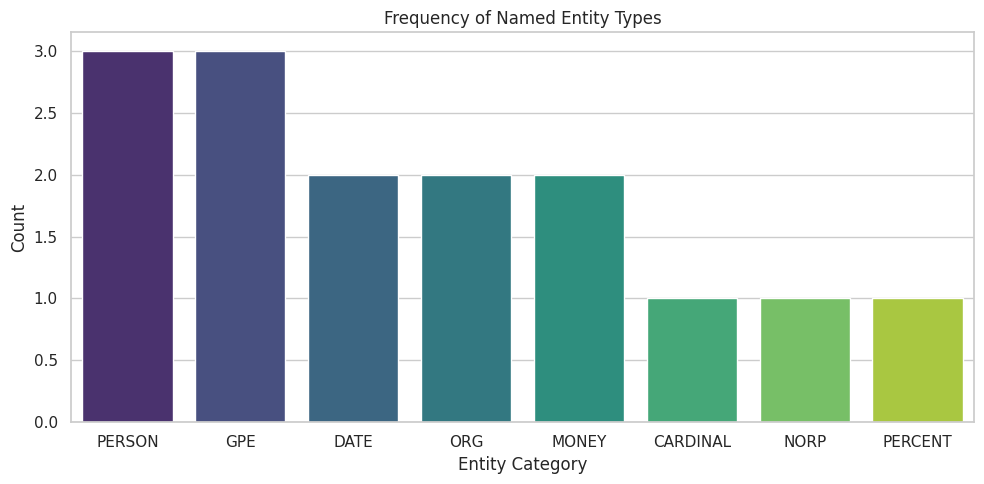

In [10]:
plt.figure(figsize=(10, 5))

sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_counts,
    x="Entity_Type",
    y="Count",
    hue="Entity_Type",
    palette="viridis",
    legend=False
)

ax.set_title("Frequency of Named Entity Types")
ax.set_xlabel("Entity Category")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

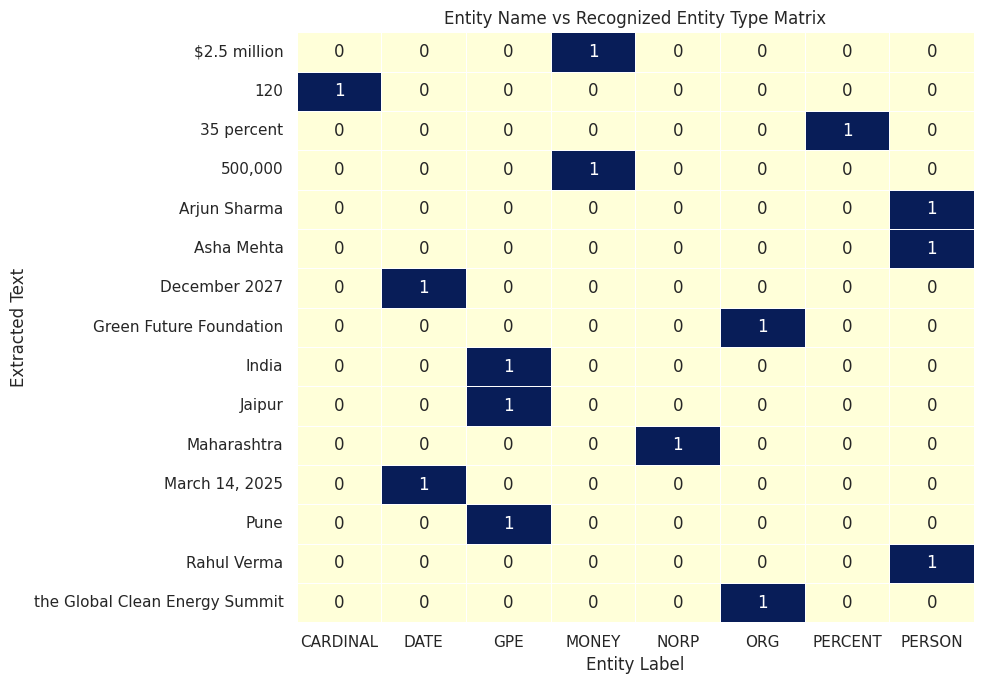

In [11]:
plt.figure(figsize=(10, 7))

ct = pd.crosstab(
    df_entities["Text"],
    df_entities["Entity Label"]
)

sns.heatmap(
    ct,
    annot=True,
    cmap="YlGnBu",
    cbar=False,
    linewidths=0.5,
    fmt="d"
)

plt.title("Entity Name vs Recognized Entity Type Matrix")
plt.xlabel("Entity Label")
plt.ylabel("Extracted Text")

plt.tight_layout()
plt.show()

In [12]:
print("FINAL NAMED ENTITY RECOGNITION RESULTS")

display(df_entities)

print("ENTITY TYPE FREQUENCY")

display(df_counts)

FINAL NAMED ENTITY RECOGNITION RESULTS


,Text,Entity Label,Description
0,"March 14, 2025",DATE,Absolute or relative dates or periods
1,Asha Mehta,PERSON,"People, including fictional"
2,the Global Clean Energy Summit,ORG,"Companies, agencies, institutions, etc."
3,Pune,GPE,"Countries, cities, states"
4,India,GPE,"Countries, cities, states"
5,Green Future Foundation,ORG,"Companies, agencies, institutions, etc."
6,Rahul Verma,PERSON,"People, including fictional"
7,Jaipur,GPE,"Countries, cities, states"
8,$2.5 million,MONEY,"Monetary values, including unit"
9,120,CARDINAL,Numerals that do not fall under another type


ENTITY TYPE FREQUENCY


,Entity_Type,Count
1,PERSON,3
3,GPE,3
0,DATE,2
2,ORG,2
4,MONEY,2
5,CARDINAL,1
6,NORP,1
7,PERCENT,1
